# Bayes and k-NN Classifiers from Scratch
Pixel-level classification of STAC satellite imagery into forest and urban landscapes.


### 1. Dataset: STAC Satellite Imagery
I use the STAC API via `pystac_client` to query and fetch cloud-free Copernicus Sentinel-2 L2A satellite imagery from AWS Earth Search. From the retrieved scene extracted two pure training regions one containing only forest pixels (Grunewald forest) and one containing only urban pixels (Berlin center). I also extracted a mixed test scene showing the border between the forest and the city.


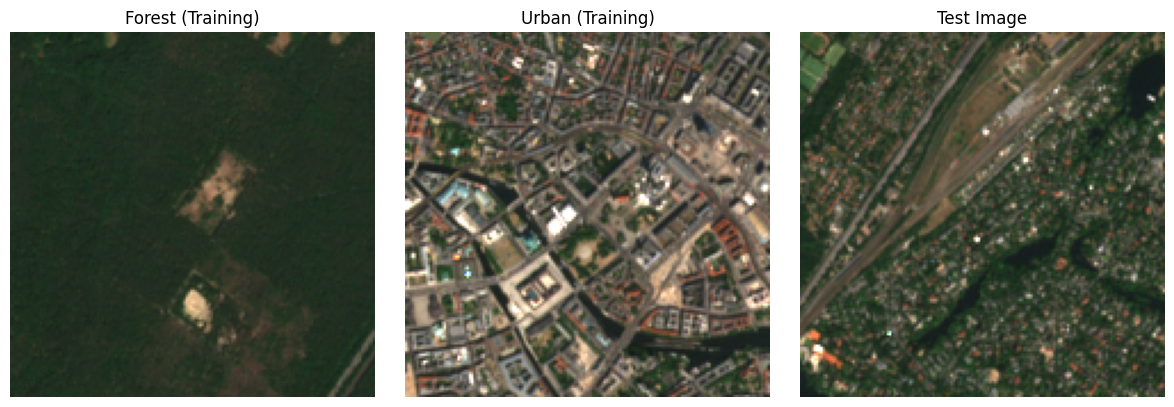

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import pystac_client
import rasterio
from rasterio.warp import transform
from rasterio.windows import Window

import functions as fn

# Query and download satellite imagery via STAC API
os.makedirs("data", exist_ok=True)
path_f = "data/satellite_forest.png"
path_u = "data/satellite_urban.png"
path_m = "data/satellite_mixed.png"

if not (os.path.exists(path_f) and os.path.exists(path_u) and os.path.exists(path_m)):
    client = pystac_client.Client.open("https://earth-search.aws.element84.com/v1")
    search = client.search(
        collections=["sentinel-2-l2a"],
        bbox=[13.2, 52.4, 13.5, 52.6],
        datetime="2023-06-01/2023-08-31",
        query={"eo:cloud_cover": {"lt": 5}},
        limit=1
    )
    item = next(search.items())
    visual_url = item.assets["visual"].href

    with rasterio.open(visual_url) as src:
        lons = [13.405, 13.220, 13.270]
        lats = [52.520, 52.470, 52.490]
        xs, ys = transform({"init": "epsg:4326"}, src.crs, lons, lats)

        targets = [(path_u, xs[0], ys[0]), (path_f, xs[1], ys[1]), (path_m, xs[2], ys[2])]
        for path, x, y in targets:
            row, col = src.index(x, y)
            win = Window(col - 80, row - 80, 160, 160)
            data = src.read(window=win)
            rgb = np.transpose(data, (1, 2, 0))
            Image.fromarray(rgb.astype(np.uint8)).save(path)

img_forest = fn.load_image(path_f)
img_urban = fn.load_image(path_u)
img_test = fn.load_image(path_m)

fn.plot_samples(img_forest, img_urban, img_test)

### 2. Feature Extraction and Parametric Gaussian PDF
To distinguish forest from urban landscapes, we compute the Excess Green Index for each pixel: ExG = 2G - R - B. 
Because vegetation strongly reflects green light while absorbing red and blue, forest pixels have high positive ExG values, whereas concrete, roads, and rooftops have lower or negative values.

Model the distribution of pixel values for each class using a 1D Gaussian (Normal) probability density function

$p(x \mid \mu, \sigma^2) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( -\frac{(x - \mu)^2}{2\sigma^2} \right)$

The parameters from the training pixels using the sample mean 

$\hat{\mu} = \frac{1}{N}\sum x_i$ and sample variance $\hat{\sigma}^2 = \frac{1}{N}\sum (x_i - \hat{\mu})^2$.


In [2]:
feat_forest = fn.extract_features(img_forest, "exg")
feat_urban = fn.extract_features(img_urban, "exg")
feat_test = fn.extract_features(img_test, "exg")

mu_f, std_f, var_f = fn.fit_gaussian_1d(feat_forest)
mu_u, std_u, var_u = fn.fit_gaussian_1d(feat_urban)

print(f"Forest parameters: mu = {mu_f:.2f}, sigma = {std_f:.2f}")
print(f"Urban parameters:  mu = {mu_u:.2f}, sigma = {std_u:.2f}")

Forest parameters: mu = 28.28, sigma = 7.83
Urban parameters:  mu = 7.97, sigma = 16.95


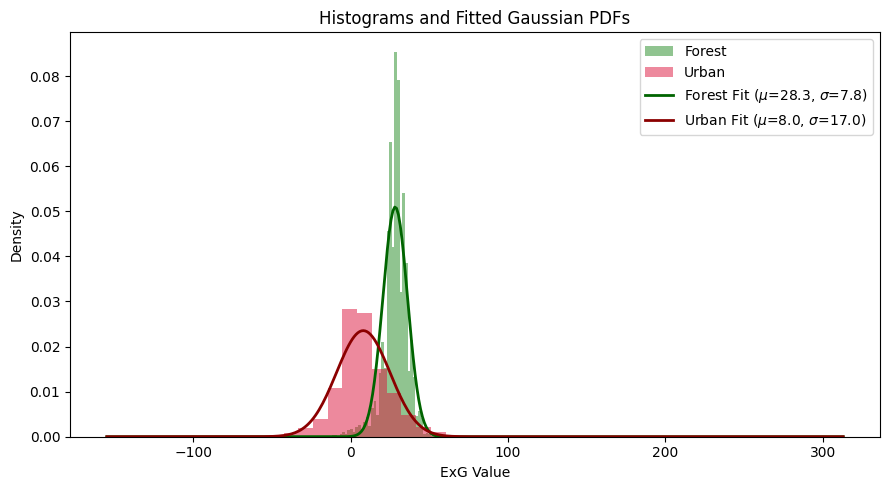

In [3]:
fn.plot_histograms_and_pdfs(feat_forest, feat_urban, mu_f, std_f, mu_u, std_u)

The histogram shows a clear separation between the two classes. Forest pixels center around a positive value with higher green dominance, while urban pixels cluster around a lower value. The fitted Gaussian curves closely follow the empirical distributions. The intersection point of the two curves serves as the decision boundary.


### 3. Bayes Decision Test
Using the fitted Gaussians and assuming equal prior probabilities ($P(\text{Forest}) = P(\text{Urban}) = 0.5$), we classify each pixel of the new test image. Assigning the pixel to forest if $p(x \mid \text{Forest}) > p(x \mid \text{Urban})$, and to urban otherwise. As requested, forest pixels are colored blue and urban pixels are colored red.


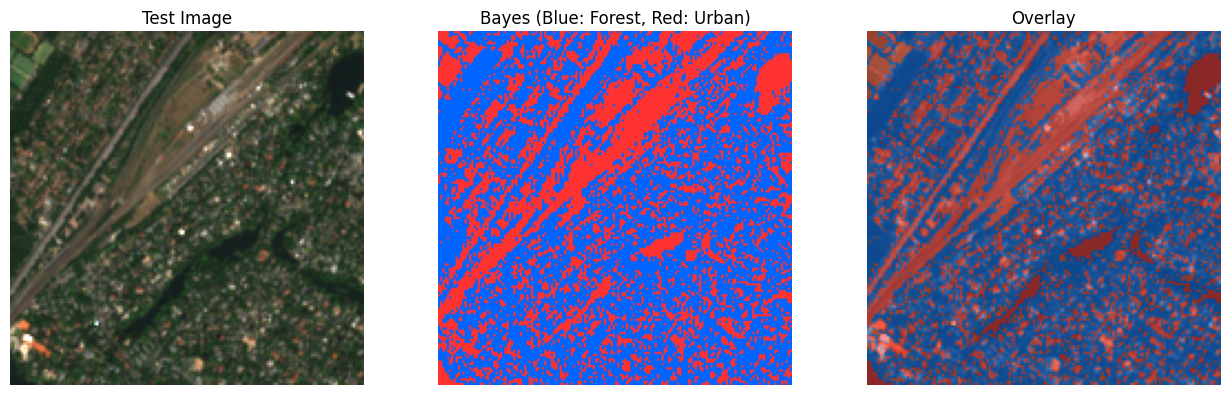

In [4]:
bayes_mask = fn.bayes_classify_1d(feat_test, mu_f, std_f, 0.5, mu_u, std_u, 0.5)
fn.plot_bayes_result(img_test, bayes_mask)

### 4. k-NN Classifier from Scratch
Next thing was designing a k-Nearest Neighbors (k-NN) classifier from scratch. Unlike Bayes, k-NN is non-parametric and makes no assumptions about Gaussian distributions. The steps of the algorithm are:

1.Store training data: Save the training samples {x_i, y_i}, where y_i in 
{1: text{Forest}, 0: text{Urban}}.

2.Compute distances: For each pixel x in the test image, compute its Euclidean distance to all training points d(x, x_i) = |x - x_i|.

3.Find nearest neighbors: Identify the k training points with the smallest distances.

4.Majority vote: Assign the class that appears most frequently among the k neighbors.


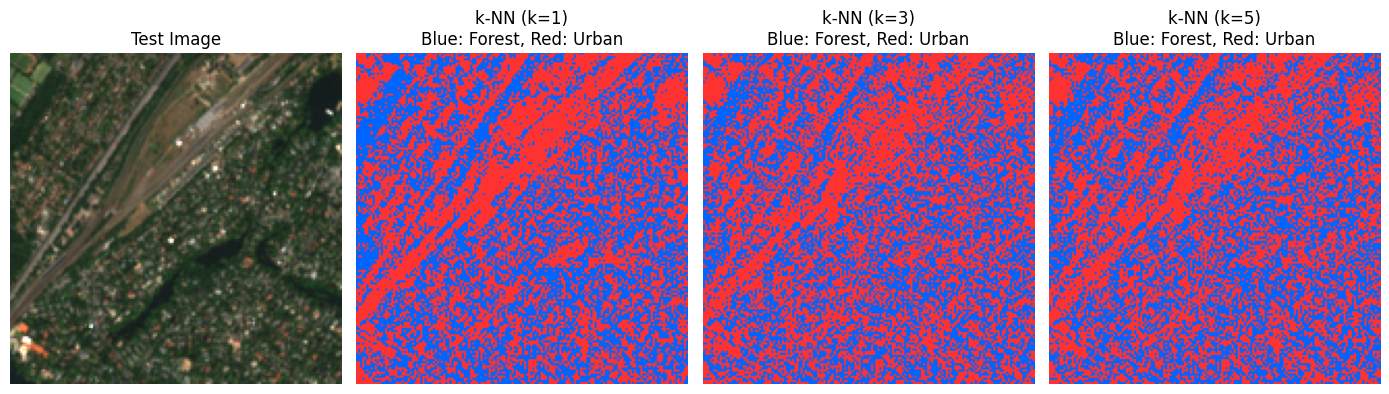

In [5]:
np.random.seed(42)
N = 800

f_flat = feat_forest.flatten()
u_flat = feat_urban.flatten()

idx_f = np.random.choice(len(f_flat), N, replace=False)
idx_u = np.random.choice(len(u_flat), N, replace=False)

X_train = np.hstack([f_flat[idx_f], u_flat[idx_u]])[:, None]
y_train = np.array([1] * N + [0] * N)
X_test = feat_test.flatten()[:, None]

knn_results = {}
for k in [1, 3, 5]:
    knn = fn.KNNClassifier(k=k)
    knn.fit(X_train, y_train)
    preds = knn.predict(X_test)
    knn_results[k] = (preds.reshape(img_test.shape[:2]) == 1)

fn.plot_knn_results(img_test, knn_results)

### 5. Observations for k = 1, 3, and 5
Changing the value of k reveals the classic bias-variance tradeoff
- At k = 1 The classifier relies on a single closest neighbor. This makes it sensitive to pixel noise and local variations in lighting or shadows, resulting in isolated misclassified pixels and jagged borders.
- At k = 3 Requiring agreement from at least 2 out of 3 neighbors filters out most isolated noisy pixels, creating more solid, uniform regions.
- At k = 5 The decision boundaries become even smoother and contiguous. Small clusters of noise disappear completely, producing a clean segmentation map very close to the Bayes classifier result.
